# Arabic Handwritten Digit Recognition using PyTorch






### 1. Import Libraries

In [1]:
import kagglehub                 # Download datasets from Kaggle

import numpy as np               # NumPy: arrays and numerical calculations
import pandas as pd              # Data handling
import matplotlib.pyplot as plt  # Matplotlib pyplot: images and graphs

import torch                     # PyTorch: neural network operations
import torch.nn as nn            # Neural network layers and models
import torch.optim as optim      # Optimization algorithms
from torch.utils.data import TensorDataset, DataLoader

### 2. Load Dataset

In [2]:
# Download the latest version of the dataset
path = kagglehub.dataset_download("mloey1/ahdd1")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'ahdd1' dataset.
Path to dataset files: /kaggle/input/ahdd1


In [3]:
import os  # Work with files and folders

print(os.listdir(path))

['csvTrainImages 60k x 784', 'csvTrainImages 60k x 784.csv', 'Arabic Handwritten Digits Dataset CSV', 'csvTestLabel 10k x 1.csv', 'csvTrainLabel 60k x 1.csv', 'Train + Test Matlab.mat', 'csvTestImages 10k x 784.csv']


### 3. Prepare X and y


In [4]:
# Read the image and label CSV files into Pandas DataFrames for easier data handling
train_images = pd.read_csv(
    os.path.join(path, "csvTrainImages 60k x 784.csv"),
    header=None
)

train_labels = pd.read_csv(
    os.path.join(path, "csvTrainLabel 60k x 1.csv"),
    header=None
)

test_images = pd.read_csv(
    os.path.join(path, "csvTestImages 10k x 784.csv"),
    header=None
)

test_labels = pd.read_csv(
    os.path.join(path, "csvTestLabel 10k x 1.csv"),
    header=None
)

In [5]:
X_train = train_images.to_numpy(dtype=np.float64)
y_train = train_labels.to_numpy().ravel()

X_test = test_images.to_numpy(dtype=np.float64)
y_test = test_labels.to_numpy().ravel()

In [6]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (60000, 784)
y_train shape: (60000,)
X_test shape: (10000, 784)
y_test shape: (10000,)


In [7]:
# Check the pixel value range
print("Training pixel range:", X_train.min(), X_train.max())
print("Testing pixel range:", X_test.min(), X_test.max())

Training pixel range: 0.0 255.0
Testing pixel range: 0.0 255.0


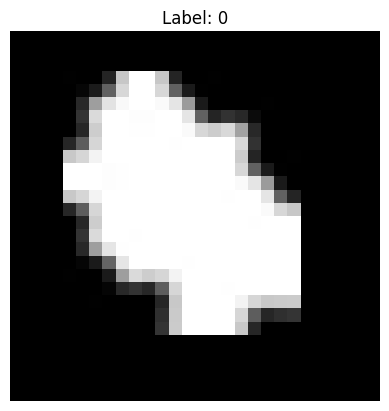

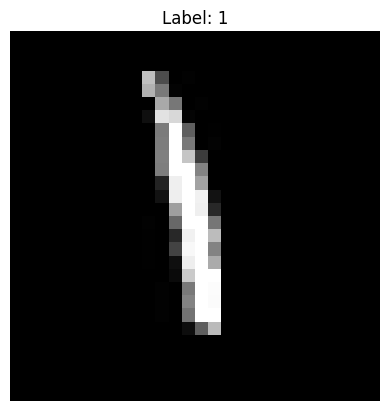

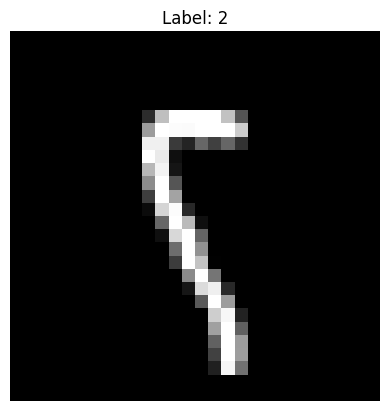

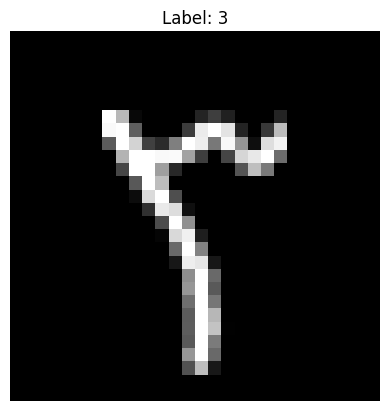

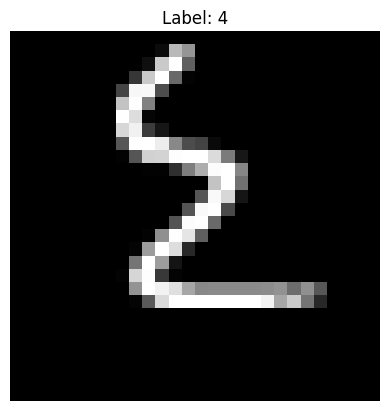

In [8]:
# Display sample images to verify their orientation and labels
## Ensure the images are displayed correctly for visual inspection
for i in range(5):
    image = X_train[i].reshape(28, 28).T # Transpose because the original image appears flipped

    plt.figure()
    plt.imshow(image, cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
    plt.show()

### 4. ANN Model

In [9]:
# Convert Numpy arrays to Pytorch tensors, and normalize the pixel values from [0, 255] to [0, 1]
X_train_tensor = torch.tensor(X_train, dtype=torch.float32) / 255.0
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32) / 255.0
y_test_tensor = torch.tensor(y_test, dtype=torch.long)


In [10]:
# Define the Artificial Neural Network
class ANN(nn.Module):
  def __init__(self, input_size, hidden_size, output_size):
     super().__init__()

     self.hidden_layer = nn.Linear(input_size, hidden_size)
     self.relu = nn.ReLU()
     self.output_layer = nn.Linear(hidden_size, output_size)

  def forward(self, x):
        x = self.hidden_layer(x)
        x = self.relu(x)
        x = self.output_layer(x)

        return x

### 5. Two-Class Experiment

In [11]:
# Select two digit classes
selected_classes = [6, 7]

# Filter training and testing data
train_mask = torch.isin(y_train_tensor, torch.tensor(selected_classes))
test_mask = torch.isin(y_test_tensor, torch.tensor(selected_classes))

X_train_two = X_train_tensor[train_mask]
y_train_two = y_train_tensor[train_mask]

X_test_two = X_test_tensor[test_mask]
y_test_two = y_test_tensor[test_mask]

print("Selected classes:", selected_classes)
print("Training samples:", X_train_two.shape)
print("Testing samples:", X_test_two.shape)

Selected classes: [6, 7]
Training samples: torch.Size([12000, 784])
Testing samples: torch.Size([2000, 784])


In [12]:
# Map selected classes to labels 0 and 1
y_train_two = (y_train_two == 7).long()
y_test_two = (y_test_two == 7).long()

print("Training labels:", torch.unique(y_train_two))
print("Testing labels:", torch.unique(y_test_two))

Training labels: tensor([0, 1])
Testing labels: tensor([0, 1])


In [13]:
# Prepare training data in mini-batches
batch_size = 128

train_dataset_two = TensorDataset(X_train_two, y_train_two)
train_loader_two = DataLoader(
    train_dataset_two,
    batch_size=batch_size,
    shuffle=True
)

In [14]:
# Set experiment parameters
input_size = 784
hidden_size = 128
output_size = 2

learning_rate = 0.01
random_seed = 42
epochs = 20

# Set random seed for reproducibility
torch.manual_seed(random_seed)

# Create the model, loss function, and optimizer
model = ANN(input_size, hidden_size, output_size)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

In [15]:
# Train the ANN using mini-batches
for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, labels in train_loader_two:
        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset_two)

    print(f"Epoch [{epoch + 1}/{epochs}], Loss: {average_loss:.4f}")

Epoch [1/20], Loss: 0.5024
Epoch [2/20], Loss: 0.1956
Epoch [3/20], Loss: 0.0964
Epoch [4/20], Loss: 0.0631
Epoch [5/20], Loss: 0.0474
Epoch [6/20], Loss: 0.0383
Epoch [7/20], Loss: 0.0323
Epoch [8/20], Loss: 0.0280
Epoch [9/20], Loss: 0.0248
Epoch [10/20], Loss: 0.0223
Epoch [11/20], Loss: 0.0202
Epoch [12/20], Loss: 0.0186
Epoch [13/20], Loss: 0.0172
Epoch [14/20], Loss: 0.0159
Epoch [15/20], Loss: 0.0149
Epoch [16/20], Loss: 0.0140
Epoch [17/20], Loss: 0.0132
Epoch [18/20], Loss: 0.0124
Epoch [19/20], Loss: 0.0118
Epoch [20/20], Loss: 0.0112


In [16]:
# Evaluate the ANN
model.eval()

with torch.no_grad():
    test_outputs = model(X_test_two)

    test_loss = criterion(test_outputs, y_test_two)

    predictions = torch.argmax(test_outputs, dim=1)
    accuracy = (predictions == y_test_two).float().mean().item() * 100

print("Selected classes:", selected_classes)
print("Learning rate:", learning_rate)
print("Random seed:", random_seed)
print(f"Test Loss: {test_loss.item():.4f}")
print(f"Test Accuracy: {accuracy:.2f}%")

Selected classes: [6, 7]
Learning rate: 0.01
Random seed: 42
Test Loss: 0.0160
Test Accuracy: 99.65%


In [17]:
# Save two-class experiment results
two_class_results = {
    "Experiment": "Two-Class",
    "Classes": str(selected_classes),
    "Learning Rate": learning_rate,
    "Seed": random_seed,
    "Accuracy": accuracy,
    "Loss": test_loss.item()
}

print(two_class_results)

{'Experiment': 'Two-Class', 'Classes': '[6, 7]', 'Learning Rate': 0.01, 'Seed': 42, 'Accuracy': 99.6500015258789, 'Loss': 0.016045374795794487}


### 6. Ten-Class Experiment


In [18]:
# Select all ten digit classes
selected_classes_ten = list(range(10))

# Prepare training data in mini-batches
train_dataset_ten = TensorDataset(X_train_tensor, y_train_tensor)
train_loader_ten = DataLoader(
    train_dataset_ten,
    batch_size=batch_size,
    shuffle=True
)

# Set random seed
torch.manual_seed(random_seed)

# Create a new model, loss function, and optimizer
model_ten = ANN(input_size, hidden_size, 10)

criterion_ten = nn.CrossEntropyLoss()
optimizer_ten = optim.SGD(model_ten.parameters(), lr=learning_rate)

print("Selected classes:", selected_classes_ten)
print("Training samples:", X_train_tensor.shape)
print("Testing samples:", X_test_tensor.shape)

Selected classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Training samples: torch.Size([60000, 784])
Testing samples: torch.Size([10000, 784])


In [19]:
# Train the ten-class ANN using mini-batches
for epoch in range(epochs):
    model_ten.train()
    total_loss_ten = 0

    for images, labels in train_loader_ten:
        optimizer_ten.zero_grad()

        outputs_ten = model_ten(images)
        loss_ten = criterion_ten(outputs_ten, labels)

        loss_ten.backward()
        optimizer_ten.step()

        total_loss_ten += loss_ten.item() * images.size(0)

    average_loss_ten = total_loss_ten / len(train_dataset_ten)

    print(f"Epoch [{epoch + 1}/{epochs}], Loss: {average_loss_ten:.4f}")

Epoch [1/20], Loss: 1.6772
Epoch [2/20], Loss: 0.6490
Epoch [3/20], Loss: 0.3741
Epoch [4/20], Loss: 0.2865
Epoch [5/20], Loss: 0.2433
Epoch [6/20], Loss: 0.2170
Epoch [7/20], Loss: 0.1988
Epoch [8/20], Loss: 0.1853
Epoch [9/20], Loss: 0.1748
Epoch [10/20], Loss: 0.1663
Epoch [11/20], Loss: 0.1593
Epoch [12/20], Loss: 0.1534
Epoch [13/20], Loss: 0.1483
Epoch [14/20], Loss: 0.1438
Epoch [15/20], Loss: 0.1399
Epoch [16/20], Loss: 0.1364
Epoch [17/20], Loss: 0.1332
Epoch [18/20], Loss: 0.1304
Epoch [19/20], Loss: 0.1278
Epoch [20/20], Loss: 0.1254


In [20]:
# Evaluate the ten-class ANN
model_ten.eval()

with torch.no_grad():
    test_outputs_ten = model_ten(X_test_tensor)

    test_loss_ten = criterion_ten(test_outputs_ten, y_test_tensor)

    predictions_ten = torch.argmax(test_outputs_ten, dim=1)
    accuracy_ten = (predictions_ten == y_test_tensor).float().mean().item() * 100

print("Selected classes:", selected_classes_ten)
print("Learning rate:", learning_rate)
print("Random seed:", random_seed)
print(f"Test Loss: {test_loss_ten.item():.4f}")
print(f"Test Accuracy: {accuracy_ten:.2f}%")

Selected classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Learning rate: 0.01
Random seed: 42
Test Loss: 0.1572
Test Accuracy: 95.72%


In [21]:
# Save ten-class experiment results
ten_class_results = {
    "Experiment": "Ten-Class",
    "Classes": str(selected_classes_ten),
    "Learning Rate": learning_rate,
    "Seed": random_seed,
    "Accuracy": accuracy_ten,
    "Loss": test_loss_ten.item()
}

print(ten_class_results)

{'Experiment': 'Ten-Class', 'Classes': '[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]', 'Learning Rate': 0.01, 'Seed': 42, 'Accuracy': 95.71999907493591, 'Loss': 0.15715545415878296}


### 7. Learning Rate Experiments

In [22]:
# Train and evaluate an ANN for a given learning rate
def run_experiment(train_dataset, X_test, y_test, output_size, lr, seed=42):
    torch.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    model = ANN(input_size, hidden_size, output_size)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)

    # Train the model
    for epoch in range(epochs):
        model.train()

        for images, labels in train_loader:
            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

    # Evaluate the model
    model.eval()

    with torch.no_grad():
        test_outputs = model(X_test)
        test_loss = criterion(test_outputs, y_test).item()

        predictions = torch.argmax(test_outputs, dim=1)
        accuracy = (predictions == y_test).float().mean().item() * 100

    return accuracy, test_loss

In [23]:
# Test different learning rates for both classification tasks
learning_rates = [0.001, 0.01, 0.1]
lr_results = []

for lr in learning_rates:
    # ----Two-class experiment----
    accuracy_two, loss_two = run_experiment(
        train_dataset_two,                     # Two-class experiment using digits 6 and 7
        X_test_two,
        y_test_two,
        output_size=2,
        lr=lr,
        seed=random_seed
    )

    lr_results.append({
        "Experiment": "Two-Class",
        "Classes": str(selected_classes),
        "Learning Rate": lr,
        "Seed": random_seed,
        "Accuracy": accuracy_two,
        "Loss": loss_two
    })

    print(f"Two-Class | LR: {lr} | Accuracy: {accuracy_two:.2f}% | Loss: {loss_two:.4f}")

    # ----Ten-class experiment----
    accuracy_ten, loss_ten = run_experiment(
        train_dataset_ten,
        X_test_tensor,
        y_test_tensor,
        output_size=10,
        lr=lr,
        seed=random_seed
    )

    lr_results.append({
        "Experiment": "Ten-Class",
        "Classes": str(selected_classes_ten),
        "Learning Rate": lr,
        "Seed": random_seed,
        "Accuracy": accuracy_ten,
        "Loss": loss_ten
    })

    print(f"Ten-Class | LR: {lr} | Accuracy: {accuracy_ten:.2f}% | Loss: {loss_ten:.4f}")

Two-Class | LR: 0.001 | Accuracy: 99.05% | Loss: 0.1329
Ten-Class | LR: 0.001 | Accuracy: 90.28% | Loss: 0.4962
Two-Class | LR: 0.01 | Accuracy: 99.65% | Loss: 0.0160
Ten-Class | LR: 0.01 | Accuracy: 95.72% | Loss: 0.1572
Two-Class | LR: 0.1 | Accuracy: 99.95% | Loss: 0.0036
Ten-Class | LR: 0.1 | Accuracy: 97.54% | Loss: 0.0878


In [24]:
# Display learning rate experiment results
lr_results_df = pd.DataFrame(lr_results)

display(lr_results_df.round({
    "Accuracy": 2,
    "Loss": 4
}))

,Experiment,Classes,Learning Rate,Seed,Accuracy,Loss
0,Two-Class,"[6, 7]",0.001,42,99.05,0.1329
1,Ten-Class,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.001,42,90.28,0.4962
2,Two-Class,"[6, 7]",0.010,42,99.65,0.0160
3,Ten-Class,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.010,42,95.72,0.1572
4,Two-Class,"[6, 7]",0.100,42,99.95,0.0036
5,Ten-Class,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.100,42,97.54,0.0878


**Observation:**

I noticed that increasing the learning rate from 0.001 to 0.1 improved the accuracy and reduced the loss in both experiments. The learning rate of 0.1 gave the best results, while 0.001 had the lowest accuracy and highest loss.

This suggests that a higher learning rate helped the model learn faster.

### 8. Random Seed Experiments


In [25]:
# Test different random seeds for both classification tasks
random_seeds = [1, 10, 42]
seed_results = []

for seed in random_seeds:
    # Two-class experiment using digits 6 and 7
    accuracy_two, loss_two = run_experiment(
        train_dataset_two,
        X_test_two,
        y_test_two,
        output_size=2,
        lr=learning_rate,
        seed=seed
    )

    seed_results.append({
        "Experiment": "Two-Class",
        "Classes": str(selected_classes),
        "Learning Rate": learning_rate,
        "Seed": seed,
        "Accuracy": accuracy_two,
        "Loss": loss_two
    })

    print(f"Two-Class | Seed: {seed} | Accuracy: {accuracy_two:.2f}% | Loss: {loss_two:.4f}")

    # Ten-class experiment using digits 0 to 9
    accuracy_ten, loss_ten = run_experiment(
        train_dataset_ten,
        X_test_tensor,
        y_test_tensor,
        output_size=10,
        lr=learning_rate,
        seed=seed
    )

    seed_results.append({
        "Experiment": "Ten-Class",
        "Classes": str(selected_classes_ten),
        "Learning Rate": learning_rate,
        "Seed": seed,
        "Accuracy": accuracy_ten,
        "Loss": loss_ten
    })

    print(f"Ten-Class | Seed: {seed} | Accuracy: {accuracy_ten:.2f}% | Loss: {loss_ten:.4f}")

Two-Class | Seed: 1 | Accuracy: 99.65% | Loss: 0.0153
Ten-Class | Seed: 1 | Accuracy: 95.65% | Loss: 0.1578
Two-Class | Seed: 10 | Accuracy: 99.65% | Loss: 0.0152
Ten-Class | Seed: 10 | Accuracy: 95.64% | Loss: 0.1576
Two-Class | Seed: 42 | Accuracy: 99.65% | Loss: 0.0160
Ten-Class | Seed: 42 | Accuracy: 95.72% | Loss: 0.1572


In [26]:
# Display the results in a table
seed_results_df = pd.DataFrame(seed_results)

display(seed_results_df.round({
    "Accuracy": 2,
    "Loss": 4
}))

,Experiment,Classes,Learning Rate,Seed,Accuracy,Loss
0,Two-Class,"[6, 7]",0.01,1,99.65,0.0153
1,Ten-Class,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.01,1,95.65,0.1578
2,Two-Class,"[6, 7]",0.01,10,99.65,0.0152
3,Ten-Class,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.01,10,95.64,0.1576
4,Two-Class,"[6, 7]",0.01,42,99.65,0.0160
5,Ten-Class,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.01,42,95.72,0.1572


In [27]:
# Compare accuracy and loss across different random seeds
for experiment in ["Two-Class", "Ten-Class"]:
    results = seed_results_df[
        seed_results_df["Experiment"] == experiment
    ]

    best_accuracy = results.loc[results["Accuracy"].idxmax()]
    lowest_loss = results.loc[results["Loss"].idxmin()]

    print(f"\n{experiment}")
    print(f"Highest Accuracy: Seed = {int(best_accuracy['Seed'])}, Accuracy = {best_accuracy['Accuracy']:.2f}%")
    print(f"Lowest Loss: Seed = {int(lowest_loss['Seed'])}, Loss = {lowest_loss['Loss']:.4f}")
    print(f"Accuracy Range: {results['Accuracy'].max() - results['Accuracy'].min():.2f} percentage points")


Two-Class
Highest Accuracy: Seed = 1, Accuracy = 99.65%
Lowest Loss: Seed = 10, Loss = 0.0152
Accuracy Range: 0.00 percentage points

Ten-Class
Highest Accuracy: Seed = 42, Accuracy = 95.72%
Lowest Loss: Seed = 42, Loss = 0.1572
Accuracy Range: 0.08 percentage points


**Observation:**

Changing the random seed had only a small effect on model performance. All three seeds for two-class produced same accuracy at 99.65% with slight differences in loss. In the ten-class experiment, accuracy ranged from 95.64% to 95.72% (a difference of 0.08%).

Therefore, these results show to us that the ANN performance was relatively stable across the tested random seeds.




### 9. Results Comparison

In [28]:
# Compare the two-class and ten-class experiments
comparison_df = pd.DataFrame([
    {
        "Number of Classes": 2,
        "Selected Classes": two_class_results["Classes"],
        "Accuracy": two_class_results["Accuracy"],
        "Loss": two_class_results["Loss"]
    },
    {
        "Number of Classes": 10,
        "Selected Classes": ten_class_results["Classes"],
        "Accuracy": ten_class_results["Accuracy"],
        "Loss": ten_class_results["Loss"]
    }
])

display(comparison_df.round({
    "Accuracy": 2,
    "Loss": 4
}))

,Number of Classes,Selected Classes,Accuracy,Loss
0,2,"[6, 7]",99.65,0.0160
1,10,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",95.72,0.1572


In [29]:
# Combine all learning rate and random seed experiments
final_results_df = pd.DataFrame(lr_results + seed_results)

# Remove repeated experiments (LR = 0.01, Seed = 42) from Sections 7 and 8
final_results_df = final_results_df.drop_duplicates(
    subset=["Experiment", "Classes", "Learning Rate", "Seed"]
)

# Organize the final table
final_results_df = final_results_df.sort_values(
    by=["Experiment", "Learning Rate", "Seed"],
    ascending=[False, True, True]
).reset_index(drop=True)

display(final_results_df.round({
    "Accuracy": 2,
    "Loss": 4
}))

,Experiment,Classes,Learning Rate,Seed,Accuracy,Loss
0,Two-Class,"[6, 7]",0.001,42,99.05,0.1329
1,Two-Class,"[6, 7]",0.010,1,99.65,0.0153
2,Two-Class,"[6, 7]",0.010,10,99.65,0.0152
3,Two-Class,"[6, 7]",0.010,42,99.65,0.0160
4,Two-Class,"[6, 7]",0.100,42,99.95,0.0036
5,Ten-Class,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.001,42,90.28,0.4962
6,Ten-Class,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.010,1,95.65,0.1578
7,Ten-Class,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.010,10,95.64,0.1576
8,Ten-Class,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.010,42,95.72,0.1572
9,Ten-Class,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",0.100,42,97.54,0.0878


### Discussion

1. Which learning rate produced the best result?

- The learning rate of 0.1 achieved the highest accuracy and lowest loss in both experiments among the three tested values.

2. How did changing the random seed affect the results?

- Changing the random seed had only a small effect on performance. The two-class accuracy remained at 99.65%, while the ten-class accuracy ranged from 95.64% to 95.72%.

3. Was two-class classification easier than ten-class classification?

- Yes. The two-class experiment achieved higher accuracy and lower loss than the ten-class experiment under the same training settings.

4. How did the loss change between experiments?

- At a learning rate of 0.01 and seed 42, the test loss increased from 0.0160 for two classes to 0.1572 for ten classes.

5. How did the accuracy change between experiments?

- Under the same settings, accuracy decreased from 99.65% for two classes to 95.72% for ten classes, a difference of 3.93 percentage points.

6. What did you learn from the experiments?

- I learned that changing the learning rate can make a big difference in the model's accuracy and loss. I also noticed that changing the random seed had only a small effect on the results. Finally, when the number of classes increased from 2 to 10, the accuracy decreased and the loss increased.





### 10. Conclusion

In this assignment, I trained an ANN to recognize handwritten Arabic digits using two-class and ten-class classification. First, I explored the dataset and displayed some images to understand the data and verify their labels. I found that each image was already flattened into 784 pixel values, representing an original 28 × 28 image, so there was no need to flatten them again. From the experiments, I noticed that increasing the number of classes from 2 to 10 reduced the accuracy and increased the loss. I also noticed a positive relationship between the learning rate and accuracy within the tested values. As the learning rate increased from 0.001 to 0.1, the accuracy improved and the loss decreased in both experiments. However, changing the random seed had only a small effect on model performance. Overall, this assignment helped me understand how to prepare image data, train an ANN, and evaluate how different settings affect its performance.